# Hybrid Conv1D+GRU -- Proper Repeated Test

Tests the exact same Hybrid Conv1D+GRU architecture from the original
exploratory notebook (0.75 accuracy, 0.38 Extra_Systole f1 on its best
run), but properly repeated (run this notebook 3+ times per dataset)
and tested on BOTH the original and re-chunked datasets -- the same
rigor applied everywhere else in this project. Previously this
architecture was only tested twice, which isn't enough to trust a
comparison against YAMNet's 3-run average.

**Set `DATASET_LABEL` below and re-run this whole notebook 3+ times per
dataset**, recording each run's Extra_Systole f1, same as every other
repeated validation in this project.

## 0. Check GPU

In [1]:
import tensorflow as tf
print("GPU devices:", tf.config.list_physical_devices('GPU'))

GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Upload your dataset

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
ZIP_NAME = "/content/drive/MyDrive/heart_project/heart_project_data.zip"  # adjust path

In [4]:
DATASET_LABEL = "Original"  # or "original" -- edit before each run

In [5]:
'''from google.colab import files
uploaded = files.upload()
ZIP_NAME = list(uploaded.keys())[0]
print("Uploaded:", ZIP_NAME)'''

'from google.colab import files\nuploaded = files.upload()\nZIP_NAME = list(uploaded.keys())[0]\nprint("Uploaded:", ZIP_NAME)'

In [6]:
import zipfile, os

EXTRACT_DIR = "/content/heart_project"
os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_NAME, 'r') as zf:
    zf.extractall(EXTRACT_DIR)

found = False
for root, dirs, files_ in os.walk(EXTRACT_DIR):
    if 'split_dataset' in dirs and 'noise_clips' in dirs:
        os.chdir(root)
        found = True
        break

if not found:
    print("WARNING: could not find split_dataset/ and noise_clips/ together.")
else:
    print(f"Dataset: {DATASET_LABEL}")
    print("Working directory:", os.getcwd())

Dataset: Original
Working directory: /content/heart_project/heart_project_data


## 2. Write shared modules

In [7]:
%%writefile spectrogram_utils.py
import numpy as np
import librosa
from scipy.signal import butter, sosfiltfilt

# --- SHARED CONFIG -- keep everything in the project pointed at this file ---
TARGET_SR = 16000
CHUNK_DURATION = 3          # seconds, matches step 1 chunking
N_FFT = 1024
HOP_LENGTH = 256
N_MELS = 64
FMAX = 800                  # PCG diagnostic content lives under ~600-800Hz

EXPECTED_SAMPLES = TARGET_SR * CHUNK_DURATION
N_FRAMES = 1 + EXPECTED_SAMPLES // HOP_LENGTH

# Heart sound diagnostic content lives in ~20-800Hz. Filtering this
# consistently on EVERY signal (real chunks AND noise clips, before any
# augmentation) removes clearly out-of-band noise/hiss/drift for free.
# It does NOT remove noise that overlaps this band (voices, rumble, fabric
# rustle) -- that's what noise-mixing augmentation is for. The two are
# complementary, not redundant.
BANDPASS_LOW_HZ = 20
BANDPASS_HIGH_HZ = 800
BANDPASS_ORDER = 4

_bandpass_sos_cache = {}

# --- Despike settings ---
# Targets isolated, single-sample-to-a-few-sample digital glitches (an
# instantaneous jump to near full-scale with quiet neighbors on both
# sides) -- distinct from genuine sustained loud/clipped audio, which
# spans many consecutive samples with a smooth attack/decay and is left
# untouched.
DESPIKE_THRESHOLD = 0.95      # near full-scale, in normalized [-1, 1] units
DESPIKE_MAX_RUN = 3           # longer runs are treated as real loud audio
DESPIKE_NEIGHBOR_QUIET = 0.3  # immediate neighbors must be well below this


def despike_glitches(y):
    """Removes isolated near-full-scale digital glitches via linear
    interpolation across the glitch, using its immediate neighbors."""
    y = y.copy()
    abs_y = np.abs(y)
    candidates = np.where(abs_y >= DESPIKE_THRESHOLD)[0]
    if len(candidates) == 0:
        return y

    groups = [[candidates[0]]]
    for idx in candidates[1:]:
        if idx - groups[-1][-1] <= 2:
            groups[-1].append(idx)
        else:
            groups.append([idx])

    for group in groups:
        if len(group) > DESPIKE_MAX_RUN:
            continue  # sustained loud region -- real audio, leave it

        start, end = group[0], group[-1]
        left, right = start - 1, end + 1
        if left < 0 or right >= len(y):
            continue

        # Only treat as a glitch if the audio was genuinely quiet right
        # before and after it -- a real transient's neighbors are still
        # elevated, not near-baseline.
        if abs_y[left] < DESPIKE_NEIGHBOR_QUIET and abs_y[right] < DESPIKE_NEIGHBOR_QUIET:
            y[left:right + 1] = np.linspace(y[left], y[right], right - left + 1)

    return y


def get_bandpass_sos(sr=TARGET_SR):
    """Cached filter coefficients -- avoids recomputing per-call."""
    if sr not in _bandpass_sos_cache:
        nyquist = sr / 2
        low = BANDPASS_LOW_HZ / nyquist
        high = min(BANDPASS_HIGH_HZ / nyquist, 0.99)
        _bandpass_sos_cache[sr] = butter(BANDPASS_ORDER, [low, high],
                                         btype='band', output='sos')
    return _bandpass_sos_cache[sr]


def apply_bandpass(y, sr=TARGET_SR):
    """Zero-phase band-pass filter, applied identically to real audio and
    noise clips alike, so nothing in the pipeline sees unfiltered content."""
    sos = get_bandpass_sos(sr)
    return sosfiltfilt(sos, y).astype(np.float32)


def load_and_filter(filepath, sr=TARGET_SR):
    """The ONE function that should load audio from disk anywhere in this
    project -- loading, resampling, despiking, and band-pass filtering
    all happen here, so training data, noise clips, and visualizations
    can never silently diverge in how they're preprocessed."""
    y, _ = librosa.load(filepath, sr=sr)
    y = despike_glitches(y)       # remove isolated digital glitches first
    return apply_bandpass(y, sr)  # then band-limit to the diagnostic range


def load_fixed_length(source, sr=TARGET_SR, is_array=False):
    """Loads audio (from filepath or an existing array) and forces it to
    exactly CHUNK_DURATION seconds. Re-run this after any augmentation
    that could change length (e.g. time-stretch). Filepath inputs are
    band-pass filtered via load_and_filter; array inputs are assumed to
    already be filtered (e.g. augmented audio that started from a
    filtered source)."""
    if is_array:
        y = source
    else:
        y = load_and_filter(source, sr)

    if len(y) > EXPECTED_SAMPLES:
        y = y[:EXPECTED_SAMPLES]
    elif len(y) < EXPECTED_SAMPLES:
        y = np.pad(y, (0, EXPECTED_SAMPLES - len(y)), mode='constant')
    return y


def audio_to_logmel(y, sr=TARGET_SR):
    """Converts a fixed-length audio array into a fixed-shape log-mel
    spectrogram: (N_MELS, N_FRAMES)."""
    S = librosa.feature.melspectrogram(
        y=y, sr=sr, n_fft=N_FFT, hop_length=HOP_LENGTH,
        n_mels=N_MELS, fmax=FMAX
    )
    S_dB = librosa.power_to_db(S, ref=np.max)

    if S_dB.shape[1] > N_FRAMES:
        S_dB = S_dB[:, :N_FRAMES]
    elif S_dB.shape[1] < N_FRAMES:
        pad_width = N_FRAMES - S_dB.shape[1]
        S_dB = np.pad(S_dB, ((0, 0), (0, pad_width)), mode='constant',
                      constant_values=S_dB.min())

    return S_dB.astype(np.float32)


def wav_to_logmel(filepath):
    """Convenience wrapper: filepath -> fixed-shape log-mel spectrogram."""
    y = load_fixed_length(filepath)
    return audio_to_logmel(y, TARGET_SR)


Writing spectrogram_utils.py


In [8]:
%%writefile augmentation_utils.py
import os
import glob
import random
import numpy as np
import librosa

from spectrogram_utils import TARGET_SR, apply_bandpass, despike_glitches

# Probabilities are applied to EVERY sample identically, regardless of
# class label. This is what structurally prevents "amount of augmentation"
# from becoming a shortcut the model can use instead of real PCG features.
SAFE_AUG_PROB = 0.5     # chance of a generic transform (stretch/volume/faint noise)
NOISE_PROB = 0.3        # chance of real recorded ESP32 noise, independent of the above
SNR_DB_RANGE = (10, 20)

# Pitch-shifting changes the exact frequency band that defines a murmur --
# left out of the default rotation for that reason.
USE_PITCH_SHIFT = False
PITCH_SHIFT_STEPS = 1

_noise_pool_cache = None


def add_faint_noise(y):
    noise = np.random.normal(0, 0.005 * np.amax(np.abs(y)), len(y))
    return y + noise


def fix_length(y, target_length):
    if len(y) > target_length:
        return y[:target_length]
    elif len(y) < target_length:
        return np.pad(y, (0, target_length - len(y)), mode='constant')
    return y


def safe_augment(y, sr):
    """One randomly chosen generic transform -- never real recorded noise."""
    target_length = len(y)
    methods = ["stretch", "volume", "faint_noise"]
    if USE_PITCH_SHIFT:
        methods.append("pitch")
    method = random.choice(methods)

    if method == "stretch":
        rate = np.random.uniform(0.93, 1.07)
        return fix_length(librosa.effects.time_stretch(y, rate=rate), target_length)
    elif method == "volume":
        scale = np.random.uniform(0.7, 1.3)
        return np.clip(y * scale, -1.0, 1.0)
    elif method == "faint_noise":
        return add_faint_noise(y)
    else:
        return librosa.effects.pitch_shift(y, sr=sr, n_steps=PITCH_SHIFT_STEPS)


def load_noise_pool(noise_dir="noise_clips", target_sr=TARGET_SR):
    """Loads and caches your recorded ESP32 noise clips into one pool."""
    global _noise_pool_cache
    if _noise_pool_cache is not None:
        return _noise_pool_cache

    files = glob.glob(os.path.join(noise_dir, "*.wav"))
    if not files:
        return None

    pool = [apply_bandpass(despike_glitches(librosa.load(f, sr=target_sr, mono=True)[0]), target_sr)
            for f in files]
    _noise_pool_cache = np.concatenate(pool)
    return _noise_pool_cache


def get_noise_segment(noise_pool, num_samples):
    if len(noise_pool) < num_samples:
        repeats = int(np.ceil(num_samples / len(noise_pool)))
        noise_pool = np.tile(noise_pool, repeats)
    start = np.random.randint(0, len(noise_pool) - num_samples + 1)
    return noise_pool[start:start + num_samples]


def mix_at_snr(signal, noise, snr_db):
    signal_power = np.mean(signal ** 2)
    noise_power = np.mean(noise ** 2)
    if noise_power == 0:
        return signal
    target_noise_power = signal_power / (10 ** (snr_db / 10))
    scale = np.sqrt(target_noise_power / noise_power)
    mixed = signal + noise * scale
    max_val = np.max(np.abs(mixed))
    if max_val > 1.0:
        mixed = mixed / max_val
    return mixed


def apply_random_augmentation(y, sr, noise_pool=None):
    """The ONE function used everywhere augmentation happens -- training
    generator and visualizations both call this, so behavior can never
    silently diverge between what you see and what the model trains on."""
    if random.random() < SAFE_AUG_PROB:
        y = safe_augment(y, sr)
    if noise_pool is not None and random.random() < NOISE_PROB:
        snr_db = np.random.uniform(*SNR_DB_RANGE)
        noise_seg = get_noise_segment(noise_pool, len(y))
        y = mix_at_snr(y, noise_seg, snr_db)
    return y


Writing augmentation_utils.py


In [9]:
%%writefile train_data_generator.py
import os
import numpy as np
import librosa
from tensorflow.keras.utils import Sequence

from spectrogram_utils import TARGET_SR, load_and_filter, load_fixed_length, audio_to_logmel
from augmentation_utils import apply_random_augmentation, load_noise_pool

TRAIN_DIR = "split_dataset/train"      # raw, unbalanced, unaugmented on disk
CLASSES = ["Normal", "Murmur", "Extra_Systole", "Artifact"]


class PCGSequence(Sequence):
    """Yields (spectrogram_batch, label_batch). With augment=True, every
    sample -- regardless of class -- has the same chance of being time
    -stretched, volume-jittered, or noise-mixed. Nothing here branches on
    class label, by design."""

    def __init__(self, batch_size=32, shuffle=True, augment=True):
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.augment = augment
        self.noise_pool = load_noise_pool() if augment else None

        self.samples = []
        for idx, cls in enumerate(CLASSES):
            class_dir = os.path.join(TRAIN_DIR, cls)
            for f in sorted(os.listdir(class_dir)):
                if f.endswith(".wav"):
                    self.samples.append((os.path.join(class_dir, f), idx))

        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.samples) / self.batch_size))

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.samples)

    def __getitem__(self, batch_idx):
        batch = self.samples[batch_idx * self.batch_size:
                              (batch_idx + 1) * self.batch_size]
        X, y = [], []

        for filepath, label in batch:
            audio = load_and_filter(filepath, TARGET_SR)
            audio = load_fixed_length(audio, is_array=True)

            if self.augment:
                audio = apply_random_augmentation(audio, TARGET_SR, self.noise_pool)
                # time-stretch can change length -- re-fix before spectrogram
                audio = load_fixed_length(audio, is_array=True)

            spec = audio_to_logmel(audio, TARGET_SR)
            X.append(spec)
            y.append(label)

        X = np.array(X, dtype=np.float32)[..., np.newaxis]
        y = np.array(y, dtype=np.int64)
        return X, y


def compute_class_weights():
    """Since the train split on disk is NOT balanced (we balance via
    class_weight instead of file duplication), pass this dict to
    model.fit(..., class_weight=...)."""
    from sklearn.utils.class_weight import compute_class_weight

    labels = []
    for idx, cls in enumerate(CLASSES):
        class_dir = os.path.join(TRAIN_DIR, cls)
        n = len([f for f in os.listdir(class_dir) if f.endswith(".wav")])
        labels += [idx] * n

    labels = np.array(labels)
    weights = compute_class_weight(class_weight="balanced",
                                    classes=np.arange(len(CLASSES)), y=labels)
    return {i: w for i, w in enumerate(weights)}


if __name__ == "__main__":
    # Quick sanity check
    seq = PCGSequence(batch_size=8, augment=True)
    X, y = seq[0]
    print(f"Batch shape: {X.shape}, labels: {y}")
    print(f"Class weights: {compute_class_weights()}")


Writing train_data_generator.py


## 3. Imports and sanity check

In [10]:
from spectrogram_utils import TARGET_SR, load_and_filter, load_fixed_length
from augmentation_utils import apply_random_augmentation, load_noise_pool
from train_data_generator import CLASSES, TRAIN_DIR, compute_class_weights
import numpy as np
print("Modules loaded OK. Classes:", CLASSES)

Modules loaded OK. Classes: ['Normal', 'Murmur', 'Extra_Systole', 'Artifact']


## 4. Load YAMNet

In [11]:
import tensorflow_hub as hub
yamnet_model = hub.load('https://tfhub.dev/google/yamnet/1')
print("YAMNet loaded.")

/usr/local/lib/python3.13/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


YAMNet loaded.


## 5. Sequential (per-frame) YAMNet embeddings -- training generator

In [12]:
from tensorflow.keras.utils import Sequence

class YamnetSequentialSequence(Sequence):
    """Yields sequential YAMNet embeddings (batch, num_frames, 1024) --
    exact same class as the original exploratory notebook."""
    def __init__(self, batch_size=32, shuffle=True, augment=True):
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.augment = augment
        self.noise_pool = load_noise_pool() if augment else None
        self.samples = []
        for idx, cls in enumerate(CLASSES):
            class_dir = os.path.join(TRAIN_DIR, cls)
            for f in sorted(os.listdir(class_dir)):
                if f.endswith(".wav"):
                    self.samples.append((os.path.join(class_dir, f), idx))
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.samples) / self.batch_size))

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.samples)

    def __getitem__(self, batch_idx):
        batch = self.samples[batch_idx * self.batch_size:(batch_idx + 1) * self.batch_size]
        X, y = [], []
        for filepath, label in batch:
            audio = load_and_filter(filepath, TARGET_SR)
            audio = load_fixed_length(audio, is_array=True)
            if self.augment:
                audio = apply_random_augmentation(audio, TARGET_SR, self.noise_pool)
                audio = load_fixed_length(audio, is_array=True)
            waveform = tf.convert_to_tensor(audio, dtype=tf.float32)
            _, embeddings, _ = yamnet_model(waveform)
            X.append(embeddings.numpy())
            y.append(label)
        return np.array(X, dtype=np.float32), np.array(y, dtype=np.int64)


train_gen_yamnet_seq = YamnetSequentialSequence(batch_size=32, shuffle=True, augment=True)
print(f"Train batches per epoch: {len(train_gen_yamnet_seq)}")

Train batches per epoch: 50


## 6. Build val/test sequential embeddings (never augmented)

In [13]:
def build_yamnet_sequential_embeddings(split_dir):
    X, y = [], []
    for class_idx, class_name in enumerate(CLASSES):
        class_dir = os.path.join(split_dir, class_name)
        files_ = sorted(f for f in os.listdir(class_dir) if f.endswith(".wav"))
        print(f"  {class_name}: {len(files_)} files")
        for f in files_:
            audio = load_and_filter(os.path.join(class_dir, f), TARGET_SR)
            audio = load_fixed_length(audio, is_array=True)
            waveform = tf.convert_to_tensor(audio, dtype=tf.float32)
            _, embeddings, _ = yamnet_model(waveform)
            X.append(embeddings.numpy())
            y.append(class_idx)
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.int64)

print("Building val sequential embeddings...")
X_val_yamnet_seq, y_val_yamnet_seq = build_yamnet_sequential_embeddings("split_dataset/val")
print("Building test sequential embeddings...")
X_test_yamnet_seq, y_test_yamnet_seq = build_yamnet_sequential_embeddings("split_dataset/test")

print(f"\nX_val_yamnet_seq shape: {X_val_yamnet_seq.shape}")
print(f"X_test_yamnet_seq shape: {X_test_yamnet_seq.shape}")

Building val sequential embeddings...
  Normal: 184 files
  Murmur: 93 files
  Extra_Systole: 29 files
  Artifact: 36 files
Building test sequential embeddings...
  Normal: 242 files
  Murmur: 84 files
  Extra_Systole: 16 files
  Artifact: 36 files

X_val_yamnet_seq shape: (342, 6, 1024)
X_test_yamnet_seq shape: (378, 6, 1024)


## 7. Build and train the Hybrid Conv1D+GRU model -- exact original architecture

In [14]:
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

def build_yamnet_hybrid_head(input_shape=(6, 1024), num_classes=4):
    inputs = layers.Input(shape=input_shape)

    x = layers.Conv1D(filters=64, kernel_size=3, padding='same', activation='relu')(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)

    x = layers.Bidirectional(layers.GRU(32, return_sequences=False, dropout=0.3, recurrent_dropout=0.3))(x)
    x = layers.BatchNormalization()(x)

    x = layers.Dense(32, activation='relu')(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    return models.Model(inputs, outputs)


model_hybrid = build_yamnet_hybrid_head()
model_hybrid.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
model_hybrid.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 6, 1024)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 6, 64)          │       196,672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 6, 64)          │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 6, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 64)             │        18,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 218,212 (852.39 KB)

 Trainable params: 217,956 (851.39 KB)

 Non-trainable params: 256 (1.00 KB)

In [15]:
class_weights_yamnet = compute_class_weights()
class_weights_yamnet[2] *= 0.7  # same overcorrection fix used everywhere else
print("Class weights:", class_weights_yamnet)

callbacks_hybrid = [
    EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-6),
    ModelCheckpoint('best_hybrid.keras', monitor='val_loss', save_best_only=True),
]

history_hybrid = model_hybrid.fit(
    train_gen_yamnet_seq,
    validation_data=(X_val_yamnet_seq, y_val_yamnet_seq),
    epochs=40,
    class_weight=class_weights_yamnet,
    callbacks=callbacks_hybrid,
)

Class weights: {0: np.float64(0.4476483762597984), 1: np.float64(0.9318181818181818), 2: np.float64(2.567201834862385), 3: np.float64(2.3794642857142856)}


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 30s 388ms/step - accuracy: 0.3202 - loss: 1.3063 - val_accuracy: 0.5643 - val_loss: 1.1536 - learning_rate: 0.0010
Epoch 2/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 19s 390ms/step - accuracy: 0.4740 - loss: 0.9979 - val_accuracy: 0.5789 - val_loss: 1.0342 - learning_rate: 0.0010
Epoch 3/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 19s 377ms/step - accuracy: 0.5147 - loss: 0.9321 - val_accuracy: 0.6199 - val_loss: 0.9577 - learning_rate: 0.0010
Epoch 4/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 19s 375ms/step - accuracy: 0.5453 - loss: 0.8884 - val_accuracy: 0.4971 - val_loss: 0.9590 - learning_rate: 0.0010
Epoch 5/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 20s 409ms/step - accuracy: 0.5378 - loss: 0.8444 - val_accuracy: 0.5439 - val_loss: 0.9066 - learning_rate: 0.0010
Epoch 6/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 19s 376ms/step - accuracy: 0.5572 - loss: 0.8291 - val_accuracy: 0.5497 - val_loss: 0.9252 - learning_rate: 0.0010
Epoch 7/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 19s 383ms/step - accuracy: 0.5666 - loss: 0.

## 8. Evaluate on the held-out test set

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.6905 - loss: 0.8708
Dataset: Original
Hybrid Conv1D+GRU -- test accuracy: 0.6905
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 70ms/step
               precision    recall  f1-score   support

       Normal       0.86      0.71      0.78       242
       Murmur       0.65      0.62      0.63        84
Extra_Systole       0.12      0.38      0.18        16
     Artifact       0.67      0.86      0.76        36

     accuracy                           0.69       378
    macro avg       0.57      0.64      0.59       378
 weighted avg       0.76      0.69      0.72       378



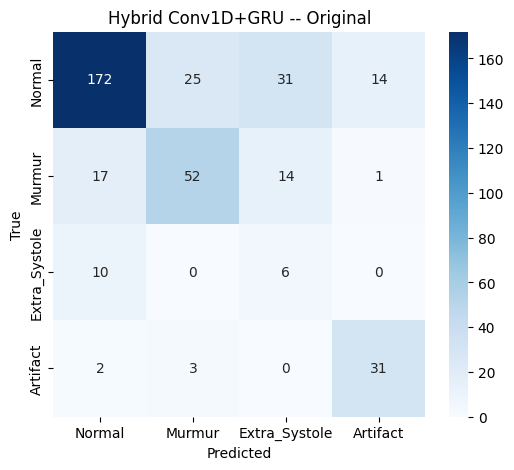


Compare against YAMNet pooled head average: 0.28 Extra_Systole f1 (original dataset, 3 runs)
Compare against Hybrid's own prior 2 runs: 0.29, 0.38 (original dataset only)


In [16]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

test_acc = model_hybrid.evaluate(X_test_yamnet_seq, y_test_yamnet_seq)[1]
print(f"Dataset: {DATASET_LABEL}")
print(f"Hybrid Conv1D+GRU -- test accuracy: {test_acc:.4f}")

y_pred = np.argmax(model_hybrid.predict(X_test_yamnet_seq), axis=1)
print(classification_report(y_test_yamnet_seq, y_pred, target_names=CLASSES, zero_division=0))

cm = confusion_matrix(y_test_yamnet_seq, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES)
plt.title(f'Hybrid Conv1D+GRU -- {DATASET_LABEL}')
plt.xlabel('Predicted'); plt.ylabel('True')
plt.show()

print(f"\nCompare against YAMNet pooled head average: 0.28 Extra_Systole f1 (original dataset, 3 runs)")
print(f"Compare against Hybrid's own prior 2 runs: 0.29, 0.38 (original dataset only)")